# 11. Advanced routing

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/11_routing_advanced.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/11_routing_advanced.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

You use the calls of `duckosm.routing` on Monaco: the `Route` object, many routes, the k best routes, a travel time
matrix, isochrones and accessibility. Each call runs in Rust on the turn graph of `route`.

| Call | Gives |
|---|---|
| `net.driving.route(a, b)` | a `Route`: `a`, `b` are edge ids, `(lon, lat)` points or place names |
| `net.driving.routes(origins, destinations)` | many routes, in parallel |
| `net.driving.k_shortest_paths(a, b, k=3)` | the `k` best routes |
| `net.driving.matrix(origins, destinations)` | a travel time matrix (a DataFrame) |
| `net.walking.isochrones(origins, minutes=[5, 10, 15])` | the polygons reached within each time |
| `net.walking.accessibility(origins, targets, minutes)` | the targets reached from each origin, and the nearest |


In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
try:                       # duckosm is there: no install
    import duckosm         # the SDK
except ImportError:        # else install it with the extras of this notebook
    %pip install -q "duckosm[widget,viz,graph]"
    import duckosm         # the SDK
print("duckosm", duckosm.__version__)    # the version

duckosm 0.8.0


## Build Monaco with two modes

In [2]:
net = duckosm.network(osm_id=2220322, modes=["driving", "walking"], name="monaco")    # get the OSM file and build the network
net                                                               # the card

cut: 34461 nodes, 5685 ways, 339 relations

Output: data/monaco.duckdb

mode,edges,nodes,km,oneway_km
driving,2840,1768,96.2,35.5
walking,11938,4589,260.6,0.0


## The Route object

A place can be a street name. The route is a `Route`: it shows a card, and it has the edges, the geometry, the steps
and a map.

In [3]:
r = net.driving.route("Boulevard Albert 1er", "Avenue Princesse Grace")    # from street to street, by car
r                                                                        # the card: edges, length, time

edges,33
length,"1,350 m"
time,2.0 min


In [4]:
r.edges[["seq", "edge_id", "name", "highway", "length_m", "cost_s"]].head()    # the first edges, in order

,seq,edge_id,name,highway,length_m,cost_s
0,0,2478527519211067132,Boulevard Albert 1er,service,105.471190,18.984814
1,1,570930183709886355,Boulevard Albert 1er,service,25.228455,4.541122
2,2,2037729375342856465,Boulevard Albert 1er,secondary,34.672100,2.496391
3,3,4052179255342490971,Rond-Point Sainte-Dévote,secondary,3.045039,0.219243
4,4,8315515182314187580,Avenue John F. Kennedy,secondary,25.473068,1.834061


In [5]:
[step["text"] for step in r.directions()][:5]    # the first turn-by-turn steps

['Head north on Boulevard Albert 1er',
 'At the roundabout, take the 1st exit onto Avenue John F. Kennedy',
 'Continue onto Boulevard Louis II',
 'At the roundabout, take the 2nd exit onto Avenue Princesse Grace',
 'Arrive at your destination']

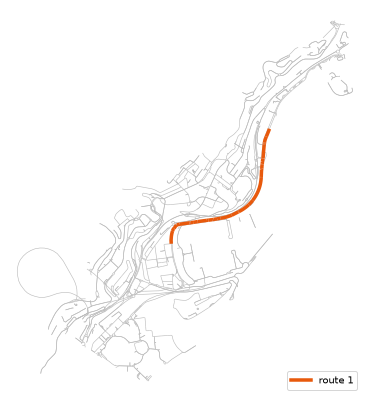

In [6]:
r.map()    # the route on the map

## The k best routes

Yen's algorithm gives the next best routes. Each route uses each edge one time only. The first route is the route of
`route`.

In [7]:
a, b = r.edge_ids[0], r.edge_ids[-1]                       # the first and the last edge of the route
best = net.driving.k_shortest_paths(a, b, k=3)              # the 3 fastest routes
[(round(x.time_s), round(x.length_m)) for x in best]        # seconds and metres of each

[(126, 1453), (127, 1459), (127, 1464)]

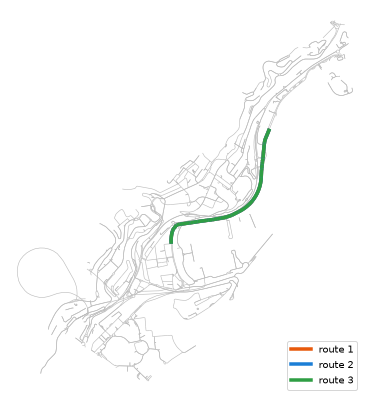

In [8]:
net.map("driving", routes={f"route {i + 1}": x for i, x in enumerate(best)})    # the 3 routes on the map

## Many routes, in parallel

`routes` takes two lists: the route goes from each origin to the destination at the same place in the list.

In [9]:
import time

edges = net.driving.edges()                                   # all driving edges
ids = edges.edge_id.sample(200, random_state=1).tolist()      # 200 edges, chosen at random
t = time.perf_counter()                                       # start the clock
many = net.driving.routes(ids[:100], ids[100:])               # 100 routes
print(f"100 routes in {time.perf_counter() - t:.2f} s")       # the time
sum(x is not None for x in many)                              # the routes found

100 routes in 0.26 s


90

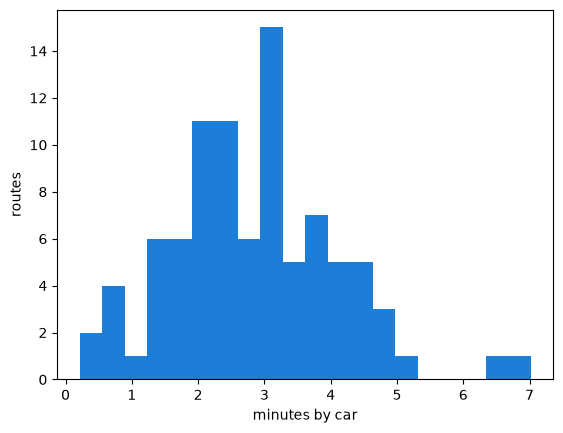

In [10]:
import matplotlib.pyplot as plt

times = [x.time_s / 60 for x in many if x is not None]        # the time of each route in minutes
plt.hist(times, bins=20, color="#1c7ed6")                     # a histogram
plt.xlabel("minutes by car"); plt.ylabel("routes"); plt.show()    # the labels

## A travel time matrix

One search from each origin reaches all destinations; the origins run in parallel. A cell is the `time_s` of the
route of that pair.

In [11]:
t = time.perf_counter()                                       # start the clock
m = net.driving.matrix(ids[:100])                             # 100 x 100 travel times in seconds
print(f"100 x 100 matrix in {time.perf_counter() - t:.2f} s") # the time
m.iloc[:5, :5].round()                                        # the first cells

100 x 100 matrix in 0.25 s


,3050652600567400442,4119412884669195015,8277540089478770184,1389707648760686556,7815454498997486282
3050652600567400442,6.0,96.0,126.0,169.0,60.0
4119412884669195015,121.0,0.0,151.0,228.0,85.0
8277540089478770184,165.0,165.0,13.0,266.0,127.0
1389707648760686556,203.0,232.0,263.0,3.0,196.0
7815454498997486282,111.0,112.0,104.0,213.0,1.0


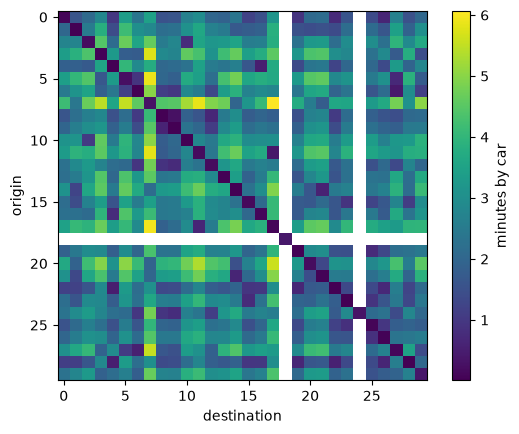

In [12]:
plt.imshow(m.iloc[:30, :30] / 60, cmap="viridis")           # a heat map of 30 x 30 cells, in minutes
plt.colorbar(label="minutes by car")                          # the scale
plt.xlabel("destination"); plt.ylabel("origin"); plt.show()   # the labels

In [13]:
round(m.iloc[0, 1]) == round(net.driving.route(ids[0], ids[1]).time_s)    # a cell equals the route

True

## Isochrones

The polygon of a time holds the edges that you reach on foot within that time. Each reached edge gets a buffer of
25 m (`buffer_m`), and the polygon is their union.

In [14]:
casino = (7.4280, 43.7393)                                           # Place du Casino
iso = net.walking.isochrones([casino], minutes=[5, 10, 15])          # three walking times
iso[["minutes", "n_edges"]]                                          # the edges reached within each time

,minutes,n_edges
0,5.0,1525
1,10.0,3483
2,15.0,5983


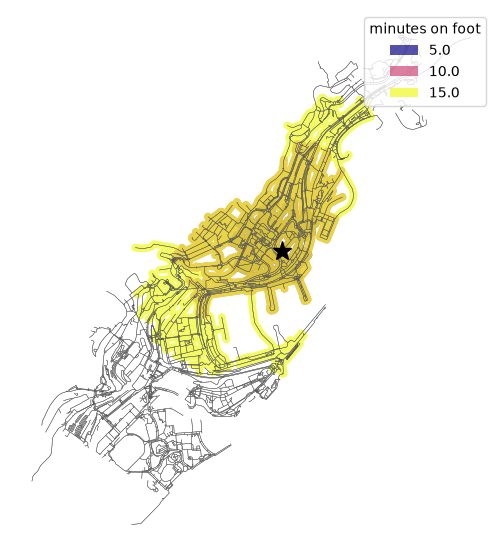

In [15]:
fig, ax = plt.subplots(figsize=(7, 7))                                           # one picture
iso.iloc[::-1].plot(ax=ax, column="minutes", categorical=True, cmap="plasma", alpha=0.7, legend=True,
                    legend_kwds={"title": "minutes on foot"})                    # the polygons, the largest below
net.walking.edges().plot(ax=ax, color="#555555", linewidth=0.3)                  # the walking roads, thin and gray
ax.plot(*casino, "k*", markersize=14); ax.set_axis_off(); plt.show()             # the start

## Accessibility

For each origin: the number of targets within each time, and the nearest target. Here the origins are walking edges,
and the targets are three points.

In [16]:
stops = [(7.4155, 43.7285), (7.4246, 43.7384), (7.4335, 43.7468)]    # three targets: Fontvieille, the port, Larvotto
homes = net.walking.edges().edge_id.tolist()                         # each walking edge is an origin
acc = net.walking.accessibility(homes, stops, minutes=[5, 10])       # the targets within 5 and 10 minutes
acc.head()                                                           # a row for each origin edge

,n_5min,n_10min,nearest,nearest_s
414242052250797,0,1,2,536.303398
901203926603589,1,1,0,279.352130
2214154189574909,0,1,0,316.343565
2362608876371269,0,0,None,NaN
2686560736896665,0,2,2,484.165528


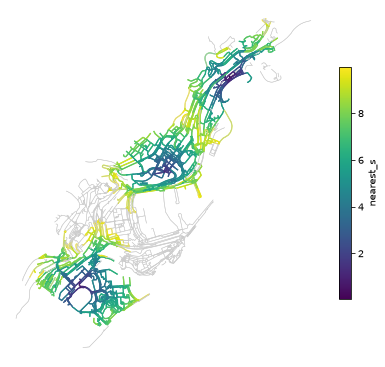

In [17]:
net.map("walking", color_by=acc["nearest_s"] / 60, cmap="viridis")    # each edge colored by the minutes to its nearest target